In [3]:
import os
print(os.getcwd())
print(os.path.exists("../data/airbnb.db"))

c:\Users\Santi\Documents\Asignaturas\Tercer semestre\Analisis de datos\FInal\_airbnb_mexico_\notebooks
True


In [4]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/airbnb.db")
df = pd.read_sql("SELECT * FROM Listings", conn)
conn.close()

print(df.shape)
df.head(3)

(30468, 91)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price_rango
0,35797,https://www.airbnb.com/rooms/35797,20260923225035,2026-09-25,NaN,Villa,"Dentro de Villa un estudio de arte con futon, ...",None,https://a0.muscache.com/pictures/f395ab78-1185...,153786,...,NaN,NaN,None,None,1,0,1,0,NaN,Premium
1,44616,https://www.airbnb.com/rooms/44616,20260923225035,2026-09-25,NaN,Condesa Haus,A new concept of hosting in mexico through a b...,None,https://a0.muscache.com/pictures/miso/Hosting-...,196253,...,4.98,4.45,None,None,10,4,3,0,0.37,Premium
2,56074,https://www.airbnb.com/rooms/56074,20260923225035,2026-09-24,NaN,Great space in historical San Rafael,This great apartment is located in one of the ...,None,https://a0.muscache.com/pictures/3005118/60dac...,265650,...,4.76,4.79,None,None,1,1,0,0,0.45,Económico


In [5]:
nulos = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(nulos[nulos > 0].to_string())


neighborhood_overview           100.0
host_thumbnail_url              100.0
host_since                      100.0
host_response_rate              100.0
host_response_time              100.0
host_acceptance_rate            100.0
bathrooms                       100.0
neighbourhood                   100.0
host_verifications              100.0
host_total_listings_count       100.0
host_neighbourhood              100.0
calendar_updated                100.0
instant_bookable                100.0
neighbourhood_group_cleansed    100.0
license                         100.0
source                           92.8
host_about                       40.6
host_location                    22.8
review_scores_checkin            13.4
review_scores_cleanliness        13.4
review_scores_accuracy           13.4
review_scores_communication      13.4
first_review                     13.4
review_scores_rating             13.4
reviews_per_month                13.4
review_scores_location           13.4
review_score

In [6]:
vacias = df.columns[df.isna().all()].tolist()
print(len(vacias), "columnas 100% vacías:")
print(vacias)

df_ok = df.drop(columns=vacias)
print(df_ok.shape)

15 columnas 100% vacías:
['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'neighbourhood_group_cleansed', 'bathrooms', 'calendar_updated', 'license', 'instant_bookable']
(30468, 76)


In [7]:
raw = pd.read_csv("../data/listings.csv.gz", compression="gzip", low_memory=False)
en_csv = [c for c in vacias if c in raw.columns]
print(raw[en_csv].isna().mean().round(3).to_string())

neighborhood_overview           1.0
host_since                      1.0
host_response_time              1.0
host_response_rate              1.0
host_acceptance_rate            1.0
host_thumbnail_url              1.0
host_neighbourhood              1.0
host_total_listings_count       1.0
host_verifications              1.0
neighbourhood                   1.0
neighbourhood_group_cleansed    1.0
bathrooms                       1.0
calendar_updated                1.0
license                         1.0
instant_bookable                1.0


## Limitaciones de los datos
El archivo `listings.csv.gz` de Ciudad de México (Inside Airbnb, 23/09/2026) trae 15 columnas completamente vacías, entre ellas host_since, host_response_rate, host_response_time, host_acceptance_rate e instant_bookable. Se excluyen del análisis. Quedan 76 columnas con datos.

In [8]:
df = df_ok.copy()
print(df.shape)

(30468, 76)


In [9]:
print(df["price"].describe().round(2).to_string())
print("Nulos:", df["price"].isna().sum(), f"({df['price'].isna().mean()*100:.1f}%)")
print(df["price"].quantile([0.01, 0.5, 0.95, 0.99]).to_string())

count      28360.00
mean        2339.92
std        14094.18
min          136.80
25%          942.20
50%         1500.00
75%         2326.62
max      1826199.19
Nulos: 2108 (6.9%)
0.01      305.0000
0.50     1500.0000
0.95     5445.6375
0.99    13476.2481


In [10]:
cols = ["id", "price", "room_type", "neighbourhood_cleansed", "accommodates", "number_of_reviews"]
print(df.nlargest(10, "price")[cols].to_string(index=False))

                 id      price       room_type neighbourhood_cleansed  accommodates  number_of_reviews
           38778769 1826199.19    Private room             Cuauhtémoc             4                227
 892676742760732948 1000300.00    Private room                Tlalpan             1                  3
1603720147099182676  790057.15 Entire home/apt         Miguel Hidalgo             2                  0
 812373795418706059  500000.00 Entire home/apt             Cuauhtémoc             5                  6
 666513486864947875  152220.00 Entire home/apt         Miguel Hidalgo            10                  0
 901962391238044233  141000.00 Entire home/apt                Tlalpan            16                  0
           52691395  140653.78 Entire home/apt             Cuauhtémoc             4                 31
 963777841659697459  130669.33 Entire home/apt             Cuauhtémoc            16                  0
           40972908  105383.00 Entire home/apt         Miguel Hidalgo    

In [11]:
tope = df["price"].quantile(0.99)
df_precio = df[df["price"] <= tope].copy()
print(f"Tope (p99): {tope:,.0f}")
print("Registros con precio:", df["price"].notna().sum())
print("Registros en df_precio:", len(df_precio))
print("Excluidos:", df["price"].notna().sum() - len(df_precio))

Tope (p99): 13,476
Registros con precio: 28360
Registros en df_precio: 28076
Excluidos: 284


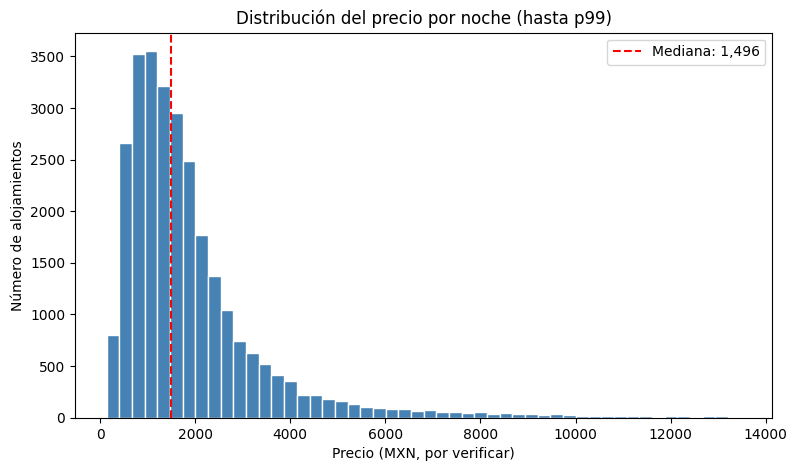

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(df_precio["price"], bins=50, color="steelblue", edgecolor="white")
plt.axvline(df_precio["price"].median(), color="red", linestyle="--", label=f"Mediana: {df_precio['price'].median():,.0f}")
plt.title("Distribución del precio por noche (hasta p99)")
plt.xlabel("Precio (MXN, por verificar)")
plt.ylabel("Número de alojamientos")
plt.legend()
plt.show()

In [13]:
print(df_precio.groupby("room_type")["price"].agg(["count", "median"]).round(0).sort_values("median", ascending=False).to_string())

                 count  median
room_type                     
Hotel room          71  2088.0
Entire home/apt  18720  1813.0
Private room      9031   847.0
Shared room        254   400.0


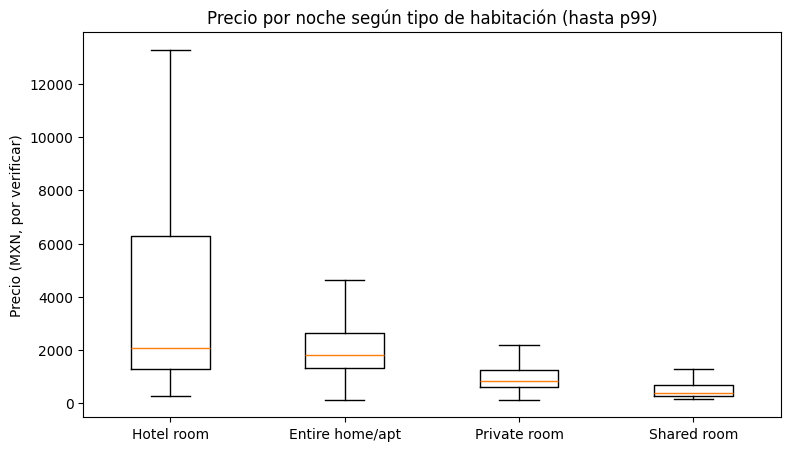

In [14]:
import matplotlib.pyplot as plt

orden = ["Hotel room", "Entire home/apt", "Private room", "Shared room"]
datos = [df_precio[df_precio["room_type"] == t]["price"] for t in orden]

plt.figure(figsize=(9, 5))
plt.boxplot(datos, tick_labels=orden, showfliers=False)
plt.title("Precio por noche según tipo de habitación (hasta p99)")
plt.ylabel("Precio (MXN, por verificar)")
plt.show()

In [15]:
t = df_precio.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"]).round(0)
print(t.sort_values("count", ascending=False).to_string())

                        count  median
neighbourhood_cleansed               
Cuauhtémoc              13084  1686.0
Miguel Hidalgo           4326  1868.0
Benito Juárez            3182  1200.0
Coyoacán                 2034  1200.0
Venustiano Carranza      1038   982.0
Tlalpan                   916   994.0
Álvaro Obregón            908  1329.0
Iztacalco                 559  1159.0
Gustavo A. Madero         547   837.0
Azcapotzalco              386   923.0
Iztapalapa                363   812.0
Cuajimalpa de Morelos     358  1789.0
Xochimilco                188  1044.0
La Magdalena Contreras    116  1020.0
Tláhuac                    46   644.0
Milpa Alta                 25   750.0


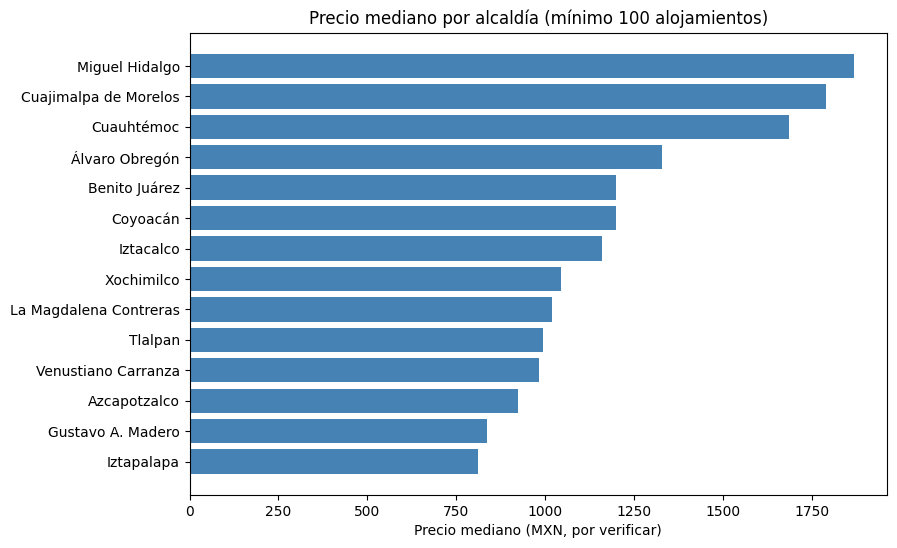

In [16]:
import matplotlib.pyplot as plt

t = df_precio.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"])
t = t[t["count"] >= 100].sort_values("median")

plt.figure(figsize=(9, 6))
plt.barh(t.index, t["median"], color="steelblue")
plt.title("Precio mediano por alcaldía (mínimo 100 alojamientos)")
plt.xlabel("Precio mediano (MXN, por verificar)")
plt.show()

In [17]:
print("Duplicados por id:", df["id"].duplicated().sum())
cols = ["accommodates", "bedrooms", "beds", "review_scores_rating", "number_of_reviews", "availability_365"]
print(df[cols].dtypes.to_string())
print(df[cols].describe().round(2).to_string())

Duplicados por id: 0
accommodates              int64
bedrooms                float64
beds                    float64
review_scores_rating    float64
number_of_reviews         int64
availability_365          int64
       accommodates  bedrooms     beds  review_scores_rating  number_of_reviews  availability_365
count      30468.00  30444.00  30039.0              26385.00           30468.00          30468.00
mean           3.43      1.53      2.0                  4.76              58.92            247.83
std            2.37      1.22      1.8                  0.38              95.34            119.10
min            1.00      0.00      1.0                  1.00               0.00              0.00
25%            2.00      1.00      1.0                  4.70               4.00            163.00
50%            3.00      1.00      2.0                  4.84              22.00            296.00
75%            4.00      2.00      2.0                  4.95              75.00            349.00
max

In [18]:
print("bedrooms > 10:", (df["bedrooms"] > 10).sum())
print("beds > 15:", (df["beds"] > 15).sum())
print("accommodates >= 12:", (df["accommodates"] >= 12).sum())
sin_rating = df[df["review_scores_rating"].isna()]
print("Sin rating:", len(sin_rating), "| de esos con 0 reseñas:", (sin_rating["number_of_reviews"] == 0).sum())

bedrooms > 10: 49
beds > 15: 62
accommodates >= 12: 581
Sin rating: 4083 | de esos con 0 reseñas: 4083


In [19]:
cols = ["price", "accommodates", "bedrooms", "beds", "review_scores_rating", "number_of_reviews", "availability_365"]
base = df_precio[df_precio["accommodates"] <= 12][cols]
print("Registros usados:", len(base))
print(base.corr(method="spearman").round(2)["price"].sort_values(ascending=False).to_string())

Registros usados: 27747
price                   1.00
accommodates            0.55
bedrooms                0.47
beds                    0.43
review_scores_rating    0.15
number_of_reviews      -0.02
availability_365       -0.07


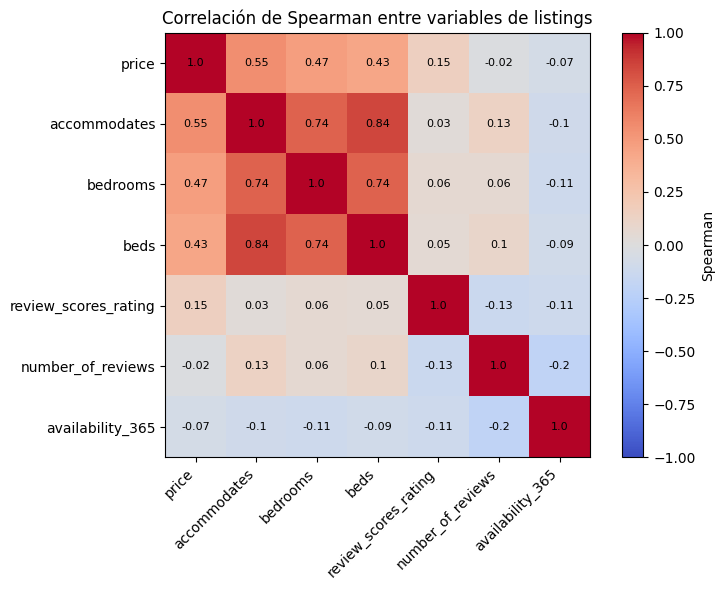

In [20]:
import matplotlib.pyplot as plt

corr = base.corr(method="spearman").round(2)

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Spearman")
plt.xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
plt.title("Correlación de Spearman entre variables de listings")
plt.tight_layout()
plt.show()

In [21]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("../data/airbnb.db")
rev_anio = pd.read_sql("SELECT anio, COUNT(*) AS reseñas FROM Reviews GROUP BY anio ORDER BY anio", conn)
conn.close()

print(rev_anio.to_string(index=False))

 anio  reseñas
 2011       54
 2012      207
 2013      491
 2014     1320
 2015     3819
 2016    11204
 2017    24717
 2018    50120
 2019    81900
 2020    53418
 2021    89223
 2022   166602
 2023   226062
 2024   306188
 2025   415226
 2026   364743


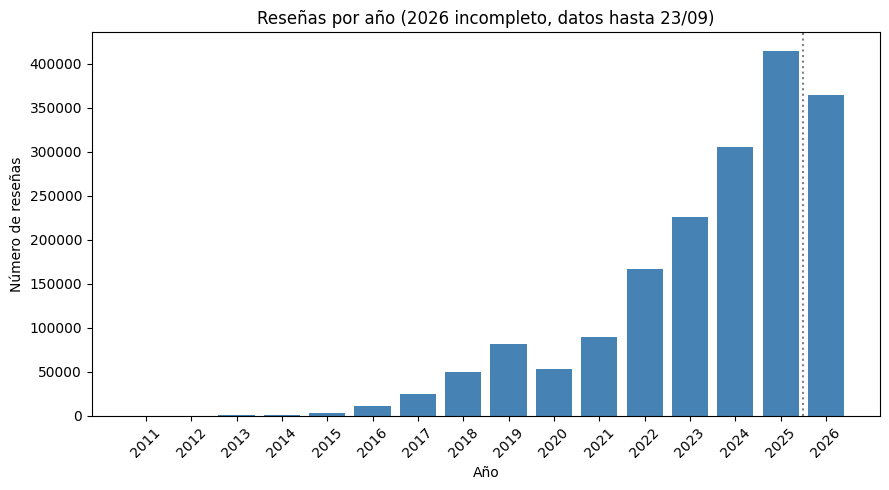

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(rev_anio["anio"].astype(str), rev_anio["reseñas"], color="steelblue")
plt.axvline(x=15 - 0.5, color="gray", linestyle=":")
plt.title("Reseñas por año (2026 incompleto, datos hasta 23/09)")
plt.xlabel("Año")
plt.ylabel("Número de reseñas")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

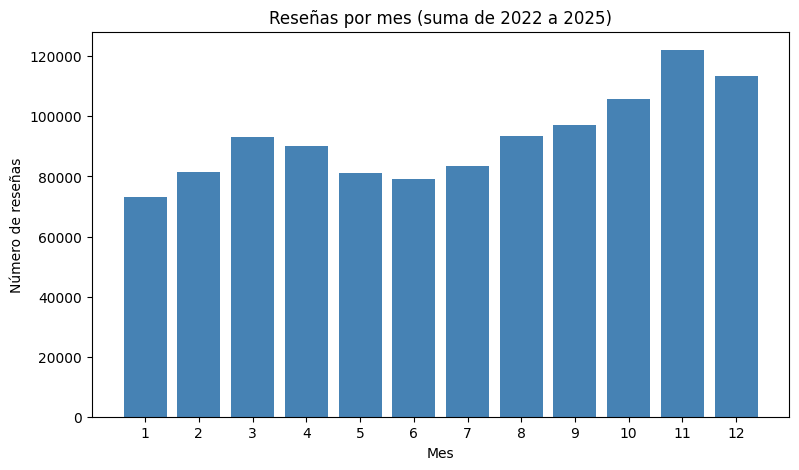

 mes  reseñas
   1    73251
   2    81346
   3    93045
   4    90209
   5    81175
   6    79252
   7    83434
   8    93612
   9    97267
  10   105841
  11   122076
  12   113570


In [23]:
conn = sqlite3.connect("../data/airbnb.db")
rev_mes = pd.read_sql(
    "SELECT mes, COUNT(*) AS reseñas FROM Reviews WHERE anio BETWEEN 2022 AND 2025 GROUP BY mes ORDER BY mes",
    conn)
conn.close()

plt.figure(figsize=(9, 5))
plt.bar(rev_mes["mes"], rev_mes["reseñas"], color="steelblue")
plt.xticks(range(1, 13))
plt.title("Reseñas por mes (suma de 2022 a 2025)")
plt.xlabel("Mes")
plt.ylabel("Número de reseñas")
plt.show()

print(rev_mes.to_string(index=False))